## imports

In [1]:
import os
import pandas as pd
import numpy as np
import json
from datetime import datetime, timedelta
import pickle

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import plotly.express as px

import io

from math import ceil

import analyze_functions
import params_scrap_syride as params

# from report_functions import PDF, get_flight_params, initialize_pdf, table_matieres, generate_pdf_report
from report_functions import generate_pdf_report, get_dfs, PDF
import report_functions as rf
# from fpdf.enums import XPos, YPos, Align

pd.set_option('display.max_columns', 1000)
pd.set_option('display.max_rows', 150)
pd.options.mode.chained_assignment = None

%load_ext autoreload
%autoreload 2

In [2]:
# Load pkl file
pkl_path = params.pkl_path
with open(pkl_path, "rb") as pkl_file:
    df = pickle.load(pkl_file)

## Création de l'heure de décolage
df["heure_decolage"] = [time.hour for time in df["heure"]]

## Création de l'url de la trace
df["flight_url"] = (
    "https://www.syride.com/fr/pilotes/"
    + df["pilote"]
    + "/"
    + df["num_activite"].astype(str)
)

display(df.sample(5))
print(df.shape[0])

,pilote,id_activite,num_activite,types,site,date,heure,flight_time,voile,distance,instrument,is_syride,date_activite,site_activite,distance_activite,distance_cumulee,vitesse_max,vitesse_moyenne,plafond,gain,duree_vol,vario_max,g_max,adresse_zip,longitude,latitude,duree_vol_minutes,type_vol,annee,mois,jour_semaine,saison,mean_longitude,mean_latitude,date_update,heure_decolage,flight_url
348,Au_Phil_du_vent,2622489,2493536,Vol moteur,Aero-Focus Ul Le Thou,2024-04-13,20:27:00,0 days 00:15:44,daytona,9,Nav XL,True,2024-04-13,Aero-Focus Ul Le Thou,9,10,73,34.3,616,591,0 days 00:15:44,2.8,2.7,https://www.syride.com/scripts/downloadZIP.php...,-0.942817,46.085967,15.733333,paramoteur,2024,avril,samedi,printemps,-0.942871,46.085988,2025-11-22 21:13:30.511271,20,https://www.syride.com/fr/pilotes/Au_Phil_du_v...
272,air race pro,810341,759829,Vol moteur,Fayards,2019-06-23,20:12:00,0 days 00:55:18,piper,29,Evolution,True,2019-06-23,Fayard,29,39,65,31.5,419,283,0 days 00:55:18,3.0,1.8,https://www.syride.com/scripts/downloadZIP.php...,0.170867,45.559767,55.300000,paramoteur,2019,juin,dimanche,été,0.172008,45.559716,2025-11-22 21:13:30.511271,20,https://www.syride.com/fr/pilotes/air race pro...
1362,air race pro,1165856,1106774,Vol treuil,Magnac Lavalette,2020-09-06,09:10:00,0 days 00:42:14,piper,22,Evolution,True,2020-09-06,Magnac Lavalette Treuil,22,30,87,31.3,580,450,0 days 00:42:14,3.1,2.2,https://www.syride.com/scripts/downloadZIP.php...,0.252517,45.486333,42.233333,paramoteur,2020,septembre,dimanche,automne,0.251879,45.488054,2025-11-22 21:13:30.511271,9,https://www.syride.com/fr/pilotes/air race pro...
393,LiLi06,2254913,2155173,Vol site,Plan De L Aiguille,2023-06-06,13:12:00,0 days 00:27:54,masala 3,7,Nav X,True,2023-06-06,Plan De L Aiguille,7,13,50,15.1,2375,86,0 days 00:27:54,1.8,1.2,https://www.syride.com/scripts/downloadZIP.php...,6.883633,45.902100,27.900000,parapente,2023,juin,mardi,été,6.883417,45.902153,2025-11-22 21:13:30.511271,13,https://www.syride.com/fr/pilotes/LiLi06/2155173
104,AUGRY,550191,533565,Vol moteur,Plateforme Dirac,2018-07-23,17:15:00,0 days 00:46:03,boxer gt,24,Nav,True,2018-07-23,Plateforme Dirac,24,27,63,31.3,750,0,0 days 00:46:03,5.0,2.2,https://www.syride.com/scripts/downloadZIP.php...,0.217184,45.609451,46.050000,paramoteur,2018,juillet,lundi,été,0.216667,45.609261,2025-11-22 21:13:30.511271,17,https://www.syride.com/fr/pilotes/AUGRY/533565


8356


In [ ]:
# pilotes = list(set(df["pilote"]))
pilotes = ["AdrienM"]
year = 2025

for pilot in pilotes:
    generate_pdf_report(df=df, pilot=pilot, year=year)

In [ ]:
pilot

In [ ]:
def get_dfs(df:pd.DataFrame, pilot:str, year:int)->pd.DataFrame:
    """
    Fonction utilisée pour obtenir les donnees de travail
    """
    df_year = df[
        df["annee"] == year
    ]
    
    df_year_pilot = df_year[
        df_year["pilote"] == pilot
    ]
    
    df_year_pilot_parapente = df_year_pilot[df_year_pilot["type_vol"]=="parapente"]
    df_year_pilot_paramoteur = df_year_pilot[df_year_pilot["type_vol"]=="paramoteur"]

    return df_year, df_year_pilot, df_year_pilot_parapente, df_year_pilot_paramoteur
def create_main_data(df:pd.DataFrame, pilot:str, year:int):
    """
    Fonction qui crée les données principales pour le rapport
    """
    report_params = {}
    report_params["pilot"] = pilot
    report_params["year_interest"] = year

    df_year, df_year_pilot, df_year_pilot_parapente, df_year_pilot_paramoteur = get_dfs(df=df, pilot=report_params["pilot"], year=report_params["year_interest"])

    return report_params, df_year, df_year_pilot, df_year_pilot_parapente, df_year_pilot_paramoteur

In [ ]:
report_params = {}
report_params["pilot"] = "AdrienM"
report_params["year_interest"] = 2025

df_year, df_year_pilot, df_year_pilot_parapente, df_year_pilot_paramoteur = get_dfs(df=df, pilot=report_params["pilot"], year=report_params["year_interest"])

print(f"""Number of traces for {report_params["pilot"]} in {report_params["year_interest"]}: {df_year_pilot.shape[0]}""")
df_year_pilot.head()

Number of traces for WIL24 in 2024: 4


,pilote,id_activite,num_activite,types,site,date,heure,flight_time,voile,distance,instrument,is_syride,date_activite,site_activite,distance_activite,distance_cumulee,vitesse_max,vitesse_moyenne,plafond,gain,duree_vol,vario_max,g_max,adresse_zip,longitude,latitude,duree_vol_minutes,type_vol,annee,mois,jour_semaine,saison,mean_longitude,mean_latitude,date_update,heure_decolage,flight_url
2,WIL24,2822474,2674852,Vol moteur,Plateforme Dirac,2024-08-05,09:02:00,0 days 00:21:38,boxer 2,9,Nav,True,2024-08-05,Plateforme Dirac,9,14,59,25.0,775,630,0 days 00:21:38,2.4,1.2,https://www.syride.com/scripts/downloadZIP.php...,0.216450,45.609083,21.633333,paramoteur,2024,aout,lundi,été,0.216272,45.609314,2025-01-06 18:45:00.154080,9,https://www.syride.com/fr/pilotes/WIL24/2674852
26,WIL24,2924589,2767651,Vol moteur,Plateforme Dirac,2024-09-28,10:07:00,0 days 00:39:09,prenium,11,Nav,True,2024-09-28,Plateforme Dirac,11,20,63,16.9,1208,1056,0 days 00:39:09,2.7,1.1,https://www.syride.com/scripts/downloadZIP.php...,0.216917,45.609467,39.150000,paramoteur,2024,septembre,samedi,automne,0.216272,45.609314,2025-01-06 18:45:00.154080,10,https://www.syride.com/fr/pilotes/WIL24/2767651
93,WIL24,2797527,2652239,Vol moteur,Plateforme Dirac,2024-07-26,09:49:00,0 days 00:35:46,boxer 2,15,Nav,True,2024-07-26,Plateforme Dirac,15,25,52,25.2,927,773,0 days 00:35:46,2.9,1.1,https://www.syride.com/scripts/downloadZIP.php...,0.216383,45.609117,35.766667,paramoteur,2024,juillet,vendredi,été,0.216272,45.609314,2025-01-06 18:45:00.154080,9,https://www.syride.com/fr/pilotes/WIL24/2652239
96,WIL24,2959365,2799324,Vol moteur,Plateforme Dirac,2024-10-28,15:45:00,0 days 00:47:04,prenium,11,Nav,True,2024-10-28,Plateforme Dirac,11,29,49,14.0,776,631,0 days 00:47:04,2.6,1.1,https://www.syride.com/scripts/downloadZIP.php...,0.216500,45.608950,47.066667,paramoteur,2024,octobre,lundi,automne,0.216272,45.609314,2025-01-06 18:45:00.154080,15,https://www.syride.com/fr/pilotes/WIL24/2799324


In [6]:
global_flight_params = get_flight_params(df=df_year_pilot)
parapente_flight_params = get_flight_params(df=df_year_pilot_parapente)
paramoteur_flight_params = get_flight_params(df=df_year_pilot_paramoteur)

In [7]:
nb_tot_minutes = int(round(df_year_pilot["duree_vol_minutes"].sum(), 0))
nb_minutes_parapente = int(round(df_year_pilot[df_year_pilot["type_vol"]=="parapente"]["duree_vol_minutes"].sum(), 0))
percent_temps_parapente = round((nb_minutes_parapente*100/nb_tot_minutes),1)
nb_minutes_paramoteur = int(round(df_year_pilot[df_year_pilot["type_vol"]=="paramoteur"]["duree_vol_minutes"].sum(), 0))
percent_temps_paramoteur = round((nb_minutes_paramoteur*100/nb_tot_minutes),1)

print(nb_tot_minutes, nb_minutes_parapente, percent_temps_parapente, nb_minutes_paramoteur, percent_temps_paramoteur)

4327 901 20.8 3426 79.2


In [8]:
def get_flight_time(serie):
    nb_tot_minutes = int(round(serie.sum(), 0))
    nb_tot_heures_pleines = nb_tot_minutes // 60
    nb_tot_minutes_pleines = nb_tot_minutes % 60
    tot_heures_vol = (
        f"{nb_tot_heures_pleines} h et {nb_tot_minutes_pleines} min"
    )
    return tot_heures_vol

def get_mean_param(serie):
    return round(serie[serie > 0].mean(), 1)

def get_max_param(serie):
    return round(serie[serie > 0].max(), 1)

def get_group(df:pd.DataFrame, col:str):
    df_group = (
        df_year_pilot
        .groupby(col, as_index=False)
        .agg(
            nb_vols = (col, "count"),
            total_duree_vol = ("duree_vol_minutes", get_flight_time),
            moyenne_duree_vol = ("duree_vol_minutes", get_mean_param),
            max_duree_vol = ("duree_vol_minutes", get_max_param),
            moyenne_vitesse_moyenne = ("vitesse_moyenne", get_mean_param),
            max_vitesse_moyenne = ("vitesse_moyenne", get_max_param),
            moyenne_vitesse_max = ("vitesse_max", get_mean_param),
            max_vitesse_max = ("vitesse_max", get_max_param),
            moyenne_gain = ("gain", get_mean_param),
            max_gain = ("gain", get_max_param),
            moyenne_vario_max = ("vario_max", get_mean_param),
            max_vario_max = ("vario_max", get_max_param),
            moyenne_g_max = ("g_max", get_mean_param),
            max_g_max = ("g_max", get_max_param),
            nb_pilotes = ("pilote", "nunique"),
            nb_tot_minutes = ("duree_vol_minutes", "sum"),
        )
        .sort_values(
            "nb_vols", ascending=False
        )
        .reset_index(drop=True)
    )
    return df_group

In [9]:
df_stat_sites = get_group(df=df_year_pilot, col="site")
df_stat_sites

,site,nb_vols,total_duree_vol,moyenne_duree_vol,max_duree_vol,moyenne_vitesse_moyenne,max_vitesse_moyenne,moyenne_vitesse_max,max_vitesse_max,moyenne_gain,max_gain,moyenne_vario_max,max_vario_max,moyenne_g_max,max_g_max,nb_pilotes,nb_tot_minutes
0,Magnac Lavalette,71,21 h et 18 min,18.0,89.6,20.5,40.8,49.8,76,365.5,1626.0,4.3,7.1,1.4,2.0,1,1278.333333
1,Site Secondigne Sur Belle 01,13,10 h et 22 min,47.8,64.3,32.7,36.6,60.5,68,452.2,711.0,2.7,3.9,1.5,2.2,1,621.516667
2,Plateforme Dirac,13,12 h et 42 min,58.6,98.7,32.6,38.4,63.6,82,703.8,851.0,2.7,4.2,1.7,3.2,1,762.066667
3,Accous-800,9,2 h et 37 min,17.4,48.1,18.6,25.8,44.1,53,NaN,NaN,1.2,1.6,1.6,2.5,1,156.583333
4,Fayards,9,6 h et 39 min,44.4,64.4,32.6,36.8,62.1,85,556.4,808.0,2.8,4.1,1.5,1.6,1,399.400000
5,Secondigne-Sur-Belle 02,8,5 h et 3 min,37.9,54.0,31.2,37.8,60.5,69,531.1,828.0,2.9,3.9,1.5,1.7,1,303.416667
6,Loudenvielle Sud,6,1 h et 0 min,10.0,11.3,19.2,22.7,43.5,48,NaN,NaN,0.1,0.1,1.6,1.9,1,60.083333
7,Ténérife Taucho,6,1 h et 17 min,12.8,21.1,16.8,21.3,44.2,50,26.0,51.0,1.3,2.4,1.4,1.5,1,76.583333
8,Val Louron,4,0 h et 54 min,13.4,16.9,19.5,23.0,42.0,46,NaN,NaN,0.3,0.5,1.6,2.2,1,53.600000
9,Ifonche,4,1 h et 6 min,16.6,29.5,19.8,25.8,45.8,46,NaN,NaN,1.4,2.4,1.4,1.5,1,66.200000


In [10]:
df_stat_voile = get_group(df=df_year_pilot, col="voile")
df_stat_voile

,voile,nb_vols,total_duree_vol,moyenne_duree_vol,max_duree_vol,moyenne_vitesse_moyenne,max_vitesse_moyenne,moyenne_vitesse_max,max_vitesse_max,moyenne_gain,max_gain,moyenne_vario_max,max_vario_max,moyenne_g_max,max_g_max,nb_pilotes,nb_tot_minutes
0,daytona,69,57 h et 6 min,49.7,98.7,32.8,40.8,61.5,85,634.8,1626,2.7,4.9,1.5,3.2,1,3426.333333
1,dolpo 3,50,8 h et 27 min,10.1,61.4,16.4,30.6,45.9,54,194.0,788,4.1,7.1,1.4,1.8,1,506.550000
2,leaf 3,33,6 h et 20 min,11.5,48.1,16.6,25.8,43.8,53,240.1,760,3.3,6.3,1.5,2.5,1,380.366667
3,boxer 2,2,0 h et 7 min,3.5,3.8,17.4,19.0,45.5,49,175.0,198,4.6,4.9,1.3,1.3,1,6.983333
4,dolpo,2,0 h et 7 min,3.4,3.7,17.8,19.3,43.0,44,162.5,164,4.7,5.2,1.3,1.4,1,6.783333


In [11]:
df_stat_type_vol = get_group(df=df_year_pilot, col="type_vol")
df_stat_type_vol

,type_vol,nb_vols,total_duree_vol,moyenne_duree_vol,max_duree_vol,moyenne_vitesse_moyenne,max_vitesse_moyenne,moyenne_vitesse_max,max_vitesse_max,moyenne_gain,max_gain,moyenne_vario_max,max_vario_max,moyenne_g_max,max_g_max,nb_pilotes,nb_tot_minutes
0,parapente,87,15 h et 1 min,10.4,61.4,16.5,30.6,45.0,54,202.7,788,3.9,7.1,1.4,2.5,1,900.683333
1,paramoteur,69,57 h et 6 min,49.7,98.7,32.8,40.8,61.5,85,634.8,1626,2.7,4.9,1.5,3.2,1,3426.333333


In [12]:
df_stat_mois_vol = get_group(df=df_year_pilot, col="mois")
ordre_mois = {
    "janvier": 1, "fevrier": 2, "mars": 3, 
    "avril": 4, "mai": 5, "juin": 6, "juillet": 7,
    "aout": 8, "septembre": 9, "octobre": 10,
    "novembre": 11, "decembre": 12,
}
df_stat_mois_vol["ordre"] = df_stat_mois_vol["mois"].map(ordre_mois)
df_stat_mois_vol = df_stat_mois_vol.sort_values(by="ordre").drop(columns=["ordre"]).reset_index(drop=True)
df_stat_mois_vol

,mois,nb_vols,total_duree_vol,moyenne_duree_vol,max_duree_vol,moyenne_vitesse_moyenne,max_vitesse_moyenne,moyenne_vitesse_max,max_vitesse_max,moyenne_gain,max_gain,moyenne_vario_max,max_vario_max,moyenne_g_max,max_g_max,nb_pilotes,nb_tot_minutes
0,janvier,7,4 h et 8 min,35.4,60.2,28.5,36.0,59.4,76,678.9,1626,3.3,4.9,1.4,1.5,1,248.033333
1,fevrier,4,1 h et 47 min,26.9,68.2,25.5,37.1,54.5,72,444.2,770,3.8,5.2,1.4,1.6,1,107.416667
2,mars,7,3 h et 40 min,31.4,56.7,33.1,38.1,54.0,59,461.0,662,2.6,3.9,1.4,1.5,1,219.966667
3,avril,24,9 h et 55 min,24.8,89.6,21.1,40.8,48.5,70,334.7,990,2.4,5.9,1.4,1.8,1,594.533333
4,mai,16,5 h et 56 min,22.2,68.6,22.9,39.2,50.2,61,323.3,771,4.0,5.2,1.4,1.7,1,355.616667
5,juin,17,6 h et 12 min,21.9,65.8,20.7,32.8,52.4,68,334.9,744,4.3,7.1,1.5,2.0,1,372.200000
6,juillet,28,9 h et 27 min,20.3,74.3,19.1,37.8,49.8,69,388.1,828,4.4,6.8,1.4,1.7,1,567.500000
7,aout,18,5 h et 50 min,19.5,51.8,21.7,39.4,46.5,60,632.7,998,1.5,3.0,1.6,2.5,1,350.450000
8,septembre,8,4 h et 29 min,33.7,63.9,25.6,38.4,55.2,67,631.1,1010,3.6,6.3,1.5,1.8,1,269.400000
9,octobre,9,7 h et 19 min,48.8,66.0,29.1,36.6,59.6,82,573.0,842,2.2,3.1,1.6,2.2,1,439.283333


In [13]:
df_stat_jour_vol = get_group(df=df_year_pilot, col="jour_semaine")
ordre_jours = {"lundi": 1, "mardi": 2, "mercredi": 3, "jeudi": 4, "vendredi": 5, "samedi": 6, "dimanche": 7}
df_stat_jour_vol["ordre"] = df_stat_jour_vol["jour_semaine"].map(ordre_jours)
df_stat_jour_vol = df_stat_jour_vol.sort_values(by="ordre").drop(columns=["ordre"]).reset_index(drop=True)
df_stat_jour_vol

,jour_semaine,nb_vols,total_duree_vol,moyenne_duree_vol,max_duree_vol,moyenne_vitesse_moyenne,max_vitesse_moyenne,moyenne_vitesse_max,max_vitesse_max,moyenne_gain,max_gain,moyenne_vario_max,max_vario_max,moyenne_g_max,max_g_max,nb_pilotes,nb_tot_minutes
0,lundi,12,6 h et 14 min,31.1,66.0,23.3,36.6,51.4,68,398.9,766,1.7,3.1,1.4,1.7,1,373.700000
1,mardi,7,4 h et 44 min,40.6,65.4,23.3,34.8,56.6,70,451.2,777,3.1,4.9,1.5,2.2,1,283.983333
2,mercredi,6,2 h et 54 min,29.1,46.7,23.4,37.8,51.5,68,434.7,511,2.2,3.3,1.4,1.7,1,174.350000
3,jeudi,16,8 h et 24 min,31.5,74.3,27.2,38.4,51.2,62,640.6,851,2.7,4.2,1.5,1.9,1,503.816667
4,vendredi,21,10 h et 38 min,30.4,66.0,24.9,36.6,53.6,69,487.8,828,2.8,5.0,1.5,2.5,1,638.383333
5,samedi,51,24 h et 57 min,29.4,98.7,24.8,39.2,53.7,82,467.2,1626,3.4,6.3,1.4,3.2,1,1497.100000
6,dimanche,43,14 h et 16 min,19.9,89.6,20.8,40.8,50.2,85,359.2,998,4.2,7.1,1.4,2.2,1,855.683333


In [14]:
df_stat_heure_vol = get_group(df=df_year_pilot, col="heure_decolage")
df_stat_heure_vol = df_stat_heure_vol.sort_values("heure_decolage").reset_index(drop=True)
df_stat_heure_vol

,heure_decolage,nb_vols,total_duree_vol,moyenne_duree_vol,max_duree_vol,moyenne_vitesse_moyenne,max_vitesse_moyenne,moyenne_vitesse_max,max_vitesse_max,moyenne_gain,max_gain,moyenne_vario_max,max_vario_max,moyenne_g_max,max_g_max,nb_pilotes,nb_tot_minutes
0,8,3,3 h et 2 min,60.7,70.2,33.9,37.6,56.3,60,659.3,729.0,2.5,2.8,1.5,1.8,1,182.133333
1,9,15,9 h et 54 min,39.6,89.6,32.2,40.8,56.8,82,672.9,990.0,2.7,4.1,1.5,1.7,1,593.916667
2,10,8,6 h et 7 min,45.9,98.7,30.4,39.4,58.2,85,617.2,998.0,2.2,3.4,1.4,1.6,1,366.816667
3,11,9,1 h et 49 min,12.1,17.8,21.0,25.8,43.4,52,NaN,NaN,0.4,1.0,1.5,2.2,1,108.816667
4,12,11,5 h et 4 min,27.6,37.7,27.2,37.8,54.2,65,435.9,628.0,2.8,3.9,1.5,1.7,1,304.150000
5,13,5,1 h et 28 min,17.6,27.1,19.9,37.7,48.8,54,303.7,472.0,4.1,6.8,1.3,1.4,1,88.066667
6,14,18,9 h et 52 min,32.9,66.1,20.9,37.2,52.4,71,345.4,766.0,3.7,6.8,1.4,1.7,1,592.400000
7,15,24,7 h et 26 min,18.6,65.4,19.2,37.0,50.1,76,336.9,851.0,4.3,6.3,1.4,3.2,1,445.900000
8,16,21,4 h et 35 min,13.1,56.7,19.0,38.1,48.7,59,332.7,1626.0,4.1,6.3,1.4,1.8,1,274.900000
9,17,14,4 h et 25 min,18.9,63.8,17.6,37.1,47.8,62,340.2,788.0,4.0,7.1,1.5,2.5,1,264.516667


## test generate_pdf_report

In [ ]:
def get_dfs(df: pd.DataFrame, pilot: str, year: int) -> pd.DataFrame:
    """
    Fonction utilisée pour obtenir les donnees de travail
    """
    df_year = df[df["annee"] == year]

    df_year_pilot = df_year[df_year["pilote"] == pilot]

    df_year_pilot_parapente = df_year_pilot[df_year_pilot["type_vol"] == "parapente"]
    df_year_pilot_paramoteur = df_year_pilot[df_year_pilot["type_vol"] == "paramoteur"]

    return df_year, df_year_pilot, df_year_pilot_parapente, df_year_pilot_paramoteur


def create_main_data(df: pd.DataFrame, pilot: str, year: int):
    """
    Fonction qui crée les données principales pour le rapport
    """
    report_params = {}
    report_params["pilot"] = pilot
    report_params["year_interest"] = year

    df_year, df_year_pilot, df_year_pilot_parapente, df_year_pilot_paramoteur = get_dfs(
        df=df, pilot=report_params["pilot"], year=report_params["year_interest"]
    )

    return (
        report_params,
        df_year,
        df_year_pilot,
        df_year_pilot_parapente,
        df_year_pilot_paramoteur,
    )


def get_flight_time(serie):
    nb_tot_minutes = int(round(serie.sum(), 0))
    nb_tot_heures_pleines = nb_tot_minutes // 60
    nb_tot_minutes_pleines = nb_tot_minutes % 60
    tot_heures_vol = f"{nb_tot_heures_pleines} h et {nb_tot_minutes_pleines} min"
    return tot_heures_vol


def get_mean_param(serie):
    return round(serie[serie > 0].mean(), 1)


def get_max_param(serie):
    return round(serie[serie > 0].max(), 1)


def get_group(df: pd.DataFrame, col: str):
    df_group = (
        df.groupby(col, as_index=False)
        .agg(
            nb_vols=(col, "count"),
            total_duree_vol=("duree_vol_minutes", get_flight_time),
            moyenne_duree_vol=("duree_vol_minutes", get_mean_param),
            max_duree_vol=("duree_vol_minutes", get_max_param),
            moyenne_vitesse_moyenne=("vitesse_moyenne", get_mean_param),
            max_vitesse_moyenne=("vitesse_moyenne", get_max_param),
            moyenne_vitesse_max=("vitesse_max", get_mean_param),
            max_vitesse_max=("vitesse_max", get_max_param),
            moyenne_gain=("gain", get_mean_param),
            max_gain=("gain", get_max_param),
            moyenne_vario_max=("vario_max", get_mean_param),
            max_vario_max=("vario_max", get_max_param),
            moyenne_g_max=("g_max", get_mean_param),
            max_g_max=("g_max", get_max_param),
            nb_pilotes=("pilote", "nunique"),
            nb_tot_minutes=("duree_vol_minutes", "sum"),
        )
        .sort_values(["moyenne_duree_vol", "total_duree_vol"], ascending=False)
        .reset_index(drop=True)
    )
    return df_group


def create_plots(df: pd.DataFrame, plot_param: dict):
    if plot_param["y_title"] is None:
        plot_param["y_title"] = plot_param["num_feature"]
    if plot_param["x_title"] is None:
        plot_param["x_title"] = plot_param["cat_feature"]

    fig = px.bar(
        data_frame=df,
        x=plot_param["cat_feature"],
        y=plot_param["num_feature"],
        text=plot_param["text"],
    )
    fig.update_traces(marker_color="orange")
    fig.update_traces(textposition="outside")
    fig.update_layout(
        showlegend=False,
        yaxis=dict(title=dict(text=plot_param["y_title"])),
        xaxis=dict(title=dict(text=plot_param["x_title"])),
        margin=dict(l=5, r=5, t=0, b=0),
    )
    return fig


def create_data_for_tables(df_init: pd.DataFrame):
    df_stat_sites = get_group(df=df_init, col="site")
    df_sites = (
        df_stat_sites[
            [
                "site",
                "nb_vols",
                "total_duree_vol",
                "moyenne_duree_vol",
                "moyenne_vitesse_moyenne",
            ]
        ]
    ).applymap(str)
    data_cols_sites = [
        [
            "Site",
            "Nombre de vols",
            "Durée totale de vol",
            "Durée moy. de vol",
            "Vitesse moyenne",
        ]
    ]
    data_rows_sites = df_sites.values.tolist()
    data_sites = data_cols_sites + data_rows_sites
    

    df_stat_voile = get_group(df=df_init, col="voile")
    df_voiles = (
        df_stat_voile[
            [
                "voile",
                "nb_vols",
                "total_duree_vol",
                "moyenne_duree_vol",
                "moyenne_vitesse_moyenne",
                "max_gain",
                "max_vario_max",
                "max_g_max",
            ]
        ]
    ).applymap(str)
    data_cols_voiles = [
        [
            "Voile",
            "Nombre de vols",
            "Durée totale de vol",
            "Durée moy. de vol",
            "Vitesse moyenne",
            "gain max",
            "vario max",
            "g max",
        ]
    ]
    data_rows_voiles = df_voiles.values.tolist()
    data_voiles = data_cols_voiles + data_rows_voiles

    return data_sites, data_voiles


def create_images(df: pd.DataFrame):
    df_stat_mois_vol = get_group(df=df, col="mois")
    ordre_mois = {
        "janvier": 1,
        "fevrier": 2,
        "mars": 3,
        "avril": 4,
        "mai": 5,
        "juin": 6,
        "juillet": 7,
        "aout": 8,
        "septembre": 9,
        "octobre": 10,
        "novembre": 11,
        "decembre": 12,
    }
    df_stat_mois_vol["ordre"] = df_stat_mois_vol["mois"].map(ordre_mois)
    df_stat_mois_vol = (
        df_stat_mois_vol.sort_values(by="ordre")
        .drop(columns=["ordre"])
        .reset_index(drop=True)
    )

    df_stat_jour_vol = get_group(df=df, col="jour_semaine")
    ordre_jours = {
        "lundi": 1,
        "mardi": 2,
        "mercredi": 3,
        "jeudi": 4,
        "vendredi": 5,
        "samedi": 6,
        "dimanche": 7,
    }
    df_stat_jour_vol["ordre"] = df_stat_jour_vol["jour_semaine"].map(ordre_jours)
    df_stat_jour_vol = (
        df_stat_jour_vol.sort_values(by="ordre")
        .drop(columns=["ordre"])
        .reset_index(drop=True)
    )

    df_stat_heure_vol = get_group(df=df, col="heure_decolage")
    df_stat_heure_vol = df_stat_heure_vol.sort_values("heure_decolage").reset_index(
        drop=True
    )

    plot_mois_dict = {
        "cat_feature": "mois",
        "num_feature": "nb_vols",
        "text": "total_duree_vol",
        "y_title": "Nombre de vols",
        "x_title": None,
    }

    plot_jour_dict = {
        "cat_feature": "jour_semaine",
        "num_feature": "nb_vols",
        "text": "total_duree_vol",
        "y_title": "Nombre de vols",
        "x_title": "Jour de la semaine",
    }

    plot_heure_dict = {
        "cat_feature": "heure_decolage",
        "num_feature": "nb_vols",
        "text": "total_duree_vol",
        "y_title": "Nombre de vols",
        "x_title": "Heure de décolage",
    }
    fig_mois = create_plots(df_stat_mois_vol, plot_param=plot_mois_dict)
    fig_jour = create_plots(df_stat_jour_vol, plot_param=plot_jour_dict)
    fig_heure = create_plots(df_stat_heure_vol, plot_param=plot_heure_dict)

    image_fig_mois = fig_mois.to_image(format="png", engine="kaleido", scale=5)
    image_fig_jour = fig_jour.to_image(format="png", engine="kaleido", scale=5)
    image_fig_heure = fig_heure.to_image(format="png", engine="kaleido", scale=5)

    image_mois = io.BytesIO(image_fig_mois)
    image_jour = io.BytesIO(image_fig_jour)
    image_heure = io.BytesIO(image_fig_heure)

    return image_mois, image_jour, image_heure

def plot_cumulative_flights(
    df_init: pd.DataFrame, 
    value_col: str = "duree_vol_minutes",
    year: int = 2025
    ):

    daily = (
        df_init
        .groupby('date', as_index=False, observed=False)
        .agg(
            duree_vol_minutes= ("duree_vol_minutes", lambda x: round(x.sum(), 0)),
        )
    )

    annee = daily['date'].dt.year.mode()[0]

    # Générer toutes les dates de l’année pour garantir une grille complète
    calendar_index = pd.date_range(start=f"{annee}-01-01", end=f"{annee}-12-31")

    df = pd.DataFrame({"date": calendar_index})
    df = df.merge(daily, on="date", how="left")
    df['duree_vol_minutes'] = df['duree_vol_minutes'].fillna(0)

    df['cumsum'] = df[value_col].cumsum()
    df['cumsum_hours'] = df['cumsum'] / 60
    
    fig_cumul_flights = plt.figure(figsize=(14, 7))
    sns.set_style("white")
    ax = sns.lineplot(data=df, x='date', y='cumsum_hours', color='#1f77b4', linewidth=2)
    
    # Fill under the line
    plt.fill_between(df['date'], df['cumsum_hours'], color='#1f77b4', alpha=0.1)
    
    # Remove spines
    sns.despine()
    
    # Add annotation at the end
    annotation_offset = min(15, len(df))  # Prendre 4 ou le nombre de lignes si moins
    if annotation_offset > 0:
        last_date = df['date'].iloc[-annotation_offset]
        last_val = (df['cumsum_hours'].iloc[-1])*1.03
        plt.text(last_date, last_val, f"{last_val:.1f} h", 
            color='#1f77b4', fontweight='bold', ha='left', va='center'
        )
    
    plt.title(f"Durée cumulée de vol - {year}", fontsize=14, fontweight='bold')
    plt.xlabel(None)
    plt.ylabel("Durée cumulée (heures)", fontsize=12)
    
    image_cumul_flights = io.BytesIO()
    fig_cumul_flights.savefig(image_cumul_flights, format='png', dpi=300, bbox_inches='tight')
    image_cumul_flights.seek(0)
    plt.close(fig_cumul_flights)
    
    return image_cumul_flights

def plot_calendar_flights(
    df_init: pd.DataFrame, 
    value_col: str = "duree_vol_minutes",
    start_month: int = 1, 
    end_month: int = 12, 
    year: int = 2025
    ):
    

    df_init['date'] = pd.to_datetime(df_init['date'])

    # Regrouper au cas où il y aurait plusieurs vols par jour
    daily = (
        df_init
        .groupby('date', as_index=False, observed=False)
        .agg(
            duree_vol_minutes= ("duree_vol_minutes", lambda x: round(x.sum(), 0)),
            type_vol = ("type_vol", "unique"), # set des types de vols dans la journée
        )
    )

    # Année que vous voulez afficher (modifiable selon vos besoins)
    annee = daily['date'].dt.year.mode()[0]

    # Générer toutes les dates de l’année pour garantir une grille complète
    calendar_index = pd.date_range(start=f"{annee}-01-01", end=f"{annee}-12-31")

    df = pd.DataFrame({"date": calendar_index})
    df = df.merge(daily, on="date", how="left")
    df['duree_vol_minutes'] = df['duree_vol_minutes'].fillna(0)

    # df = df_init.copy()
    df = df[
        (df['date'].dt.year == year)
        & (df['date'].dt.month >= start_month) 
        & (df['date'].dt.month <= end_month)
    ]
    df['month']=df['date'].dt.month
    vmax=df[value_col].max()

    nb_jour_vol = len(df[df["duree_vol_minutes"]>0])
    temps_vol_moyen = round(df[df["duree_vol_minutes"]>0]["duree_vol_minutes"].mean(), 0)
    
    months = sorted(df['month'].unique())
    cols = 3; 
    rows = ceil(len(months)/cols)


    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 3.2*rows))
    axes = np.array(axes).reshape(rows, cols)
    mois_noms = {
        1:'Jan', 2:'Fév', 3:'Mar', 4:'Avr', 5:'Mai', 
        6:"Jun", 7:'Jul', 8:'Aout', 9:"Sep", 10:'Oct', 
        11:'Nov', 12: 'Déc'
    }
    
    for i,m in enumerate(months):
        ax = axes[i//cols, i%cols]
        sub = df[df['month']==m].set_index('date')
        first = pd.Timestamp(year=year, month=m, day=1)
        last = first + pd.offsets.MonthEnd(0)
        
        rng = pd.date_range(first, last, freq='D')
        tmp = pd.DataFrame(index=rng)

        tmp[value_col] = sub[value_col]
        tmp['type_vol'] = sub['type_vol']
        
        val_param, val_para, val_both = [], [], []
        for _, row in tmp.iterrows():
            v = row[value_col]
            t = row['type_vol']
            is_param = False
            is_para = False
            if pd.notna(v) and v > 0 and isinstance(t, (list, np.ndarray)):
                if 'paramoteur' in t: is_param = True
                if 'parapente' in t: is_para = True
            
            if is_param and is_para:
                val_both.append(v)
                val_param.append(np.nan)
                val_para.append(np.nan)
            elif is_param:
                val_both.append(np.nan)
                val_param.append(v)
                val_para.append(np.nan)
            elif is_para:
                val_both.append(np.nan)
                val_param.append(np.nan)
                val_para.append(v)
            else:
                val_both.append(np.nan)
                val_param.append(np.nan)
                val_para.append(np.nan)

        tmp['val_param'] = val_param
        tmp['val_para'] = val_para
        tmp['val_both'] = val_both

        tmp['dow']= tmp.index.weekday
        tmp['week']= tmp.index.isocalendar().week
        if tmp["week"].min()> 50:
            tmp["week"] -= tmp["week"].min()
            
        p_param = tmp.pivot(index='week', columns='dow', values='val_param').astype(float)
        p_para = tmp.pivot(index='week', columns='dow', values='val_para').astype(float)
        p_both = tmp.pivot(index='week', columns='dow', values='val_both').astype(float)
        
        sns.heatmap(p_param, ax=ax, cmap='Greens', cbar=False, vmin=0, vmax=vmax, linewidths=.5, linecolor='white', annot=True, fmt=".0f")
        sns.heatmap(p_para, ax=ax, cmap='Reds', cbar=False, vmin=0, vmax=vmax, linewidths=.5, linecolor='white', annot=True, fmt=".0f")
        sns.heatmap(p_both, ax=ax, cmap='Purples', cbar=False, vmin=0, vmax=vmax, linewidths=.5, linecolor='white', annot=True, fmt=".0f")

        ax.set_title(f"{mois_noms[m]} {year}")
        ax.set_xticks([0.5,1.5,2.5,3.5,4.5,5.5,6.5])
        ax.set_xticklabels(['Lun','Mar','Mer','Jeu', 'Ven','Sam','Dim'], rotation=0, fontsize=8)
        ax.set_ylabel('Sem.')
        ax.set_xlabel(None)
    
    for j in range(i+1, rows*cols): 
        fig.delaxes(axes[j//cols, j%cols])
    
    legend_elements = [
        Patch(facecolor='green', label='Vol paramoteur'),
        Patch(facecolor='red', label='Vol parapente'),
        Patch(facecolor='purple', label='Vol parapente et paramoteur'),
    ]
    fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.025), ncol=3, fontsize=10)
    fig.suptitle(f"Calendrier des vols - {year}, {nb_jour_vol} jours avec vols , {round(temps_vol_moyen, 0)} minutes de vol en moyenne", fontsize=14, fontweight='bold', ha='center')
    
    
    plt.tight_layout()
    
    image_calendrier_flights = io.BytesIO()
    fig.savefig(image_calendrier_flights, format='png', dpi=300, bbox_inches='tight')
    image_calendrier_flights.seek(0)
    plt.close(fig)
    
    return image_calendrier_flights

def generate_pdf_report1(
    df: pd.DataFrame,
    pilot: str,
    year: int,
    folder_name: str = "/Users/Adrien/Documents/paramoteur/syride/analyze_traces/syride_traces/pdf_reports/",
):
    file_name = f"{pilot}_stats_vol_{year}.pdf"
    final_file_name = folder_name + file_name
    (
        report_params,
        _,
        df_year_pilot,
        df_year_pilot_parapente,
        df_year_pilot_paramoteur,
    ) = create_main_data(df=df, pilot=pilot, year=year)
    # display(df_year_pilot.head())
    # display(df_year_pilot_parapente.head())
    # display(df_year_pilot_paramoteur.head())

    report_params["syride_pilote_url"] = f"https://www.syride.com/fr/pilotes/{pilot}"

    if df_year_pilot.shape[0] > 0:
        report_params["title"] = (
            f"""Statistiques des vols pour l'année {report_params["year_interest"]}"""
        )
        chapters_dict = {
            "1": "Statistiques générales",
            "2": "Statistiques parapente",
            "3": "Statistiques paramoteur",
        }
        tables_dict = {
            "table_1_title": "Sites pratiqués :",
            "table_2_title": "Voiles utilisées :",
        }

        # Creation du rapport PDF
        pdf = rf.initialize_pdf(report_params=report_params)
        links_dict, pdf = rf.table_matieres(pdf=pdf, chapters_dict=chapters_dict)

        # Chapter 1: Global
        # Variables
        global_flight_params = rf.get_flight_params(df=df_year_pilot)
        data_sites, data_voiles = create_data_for_tables(df_init=df_year_pilot)
        image_mois, image_jour, image_heure = create_images(df=df_year_pilot)
        image_cumul_flights = plot_cumulative_flights(df_init=df_year_pilot, year=year)
        image_calendrier_flights = plot_calendar_flights(df_init=df_year_pilot, year=year)

        pdf.print_chapter(
            chap_num=1, chap_title=chapters_dict["1"], link=links_dict["1"]
        )
        pdf.general_stats(df=df_year_pilot, flight_params_dict=global_flight_params)
        pdf.ln(10)
        pdf.image(name=image_cumul_flights, x=20, w=pdf.w - 30, keep_aspect_ratio=True)
        pdf.image(name=image_calendrier_flights, x=20, w=pdf.w - 30, keep_aspect_ratio=True)
        pdf.ln(10)
        pdf.create_table(data=data_sites, table_title=tables_dict["table_1_title"])
        pdf.ln(5)
        pdf.create_table(data=data_voiles, table_title=tables_dict["table_2_title"])
        pdf.image(name=image_mois, x=20, w=pdf.w - 30, keep_aspect_ratio=True)
        pdf.image(name=image_jour, x=30, w=pdf.w - 60, keep_aspect_ratio=True)
        pdf.image(name=image_heure, x=20, w=pdf.w - 50, keep_aspect_ratio=True)

        # Chapter 2: parapente
        pdf.print_chapter(
            chap_num=2, chap_title=chapters_dict["2"], link=links_dict["2"]
        )
        if df_year_pilot_parapente.shape[0] > 0:
            # variables
            parapente_flight_params = rf.get_flight_params(df=df_year_pilot_parapente)
            data_sites_parapente, data_voiles_parapente = create_data_for_tables(
                df_init=df_year_pilot_parapente
            )
            image_mois_parapente, image_jour_parapente, image_heure_parapente = (
                create_images(df=df_year_pilot_parapente)
            )
            image_cumul_flights_parapente = plot_cumulative_flights(df_init=df_year_pilot_parapente, year=year)
            image_calendrier_flights_parapente = plot_calendar_flights(df_init=df_year_pilot_parapente, year=year)

            # pdf
            pdf.general_stats(
                df=df_year_pilot_parapente, flight_params_dict=parapente_flight_params
            )
            pdf.ln(10)
            pdf.image(name=image_cumul_flights_parapente, x=20, w=pdf.w - 30, keep_aspect_ratio=True)
            pdf.image(name=image_calendrier_flights_parapente, x=20, w=pdf.w - 30, keep_aspect_ratio=True)
            pdf.ln(10)
            pdf.create_table(
                data=data_sites_parapente, table_title=tables_dict["table_1_title"]
            )
            pdf.ln(5)
            pdf.create_table(
                data=data_voiles_parapente, table_title=tables_dict["table_2_title"]
            )
            pdf.image(
                name=image_mois_parapente, x=20, w=pdf.w - 30, keep_aspect_ratio=True
            )
            pdf.image(
                name=image_jour_parapente, x=30, w=pdf.w - 60, keep_aspect_ratio=True
            )
            pdf.image(
                name=image_heure_parapente, x=20, w=pdf.w - 50, keep_aspect_ratio=True
            )
        else:
            pdf.set_font("helvetica", size=11)
            pdf.cell(
                w=0,
                h=5,
                text="Aucune activité parapente connue",
                new_x=XPos.LMARGIN,
                new_y=YPos.NEXT,
            )

        # Chapter 3: paramoteur
        pdf.print_chapter(
            chap_num=3, chap_title=chapters_dict["3"], link=links_dict["3"]
        )
        if df_year_pilot_paramoteur.shape[0] > 0:
            # Variables
            paramoteur_flight_params = rf.get_flight_params(df=df_year_pilot_paramoteur)
            data_sites_paramoteur, data_voiles_paramoteur = create_data_for_tables(
                df_init=df_year_pilot_paramoteur
            )
            image_mois_paramoteur, image_jour_paramoteur, image_heure_paramoteur = (
                create_images(df=df_year_pilot_paramoteur)
            )
            image_cumul_flights_paramoteur = plot_cumulative_flights(df_init=df_year_pilot_paramoteur, year=year)
            image_calendrier_flights_paramoteur = plot_calendar_flights(df_init=df_year_pilot_paramoteur, year=year)

            # pdf
            pdf.general_stats(
                df=df_year_pilot_paramoteur, flight_params_dict=paramoteur_flight_params
            )
            pdf.ln(10)
            pdf.image(name=image_cumul_flights_paramoteur, x=20, w=pdf.w - 30, keep_aspect_ratio=True)
            pdf.image(name=image_calendrier_flights_paramoteur, x=20, w=pdf.w - 30, keep_aspect_ratio=True)
            pdf.ln(10)
            pdf.create_table(
                data=data_sites_paramoteur, table_title=tables_dict["table_1_title"]
            )
            pdf.ln(5)
            pdf.create_table(
                data=data_voiles_paramoteur, table_title=tables_dict["table_2_title"]
            )
            pdf.image(
                name=image_mois_paramoteur, x=20, w=pdf.w - 30, keep_aspect_ratio=True
            )
            pdf.image(
                name=image_jour_paramoteur, x=30, w=pdf.w - 60, keep_aspect_ratio=True
            )
            pdf.image(
                name=image_heure_paramoteur, x=20, w=pdf.w - 50, keep_aspect_ratio=True
            )
        else:
            pdf.set_font("helvetica", size=11)
            pdf.cell(
                w=0,
                h=5,
                text="Aucune activité paramoteur connue",
                new_x=XPos.LMARGIN,
                new_y=YPos.NEXT,
            )

        pdf.output(final_file_name)
        print(f"Rapport PDF généré : {file_name}")

,date,duree_vol_minutes,cumsum,cumsum_hours
0,2025-01-01,0.0,0.0,0.000000
1,2025-01-02,0.0,0.0,0.000000
2,2025-01-03,0.0,0.0,0.000000
3,2025-01-04,0.0,0.0,0.000000
4,2025-01-05,0.0,0.0,0.000000
5,2025-01-06,0.0,0.0,0.000000
6,2025-01-07,0.0,0.0,0.000000
7,2025-01-08,0.0,0.0,0.000000
8,2025-01-09,0.0,0.0,0.000000
9,2025-01-10,0.0,0.0,0.000000


Rapport PDF généré : AdrienM_stats_vol_2025.pdf


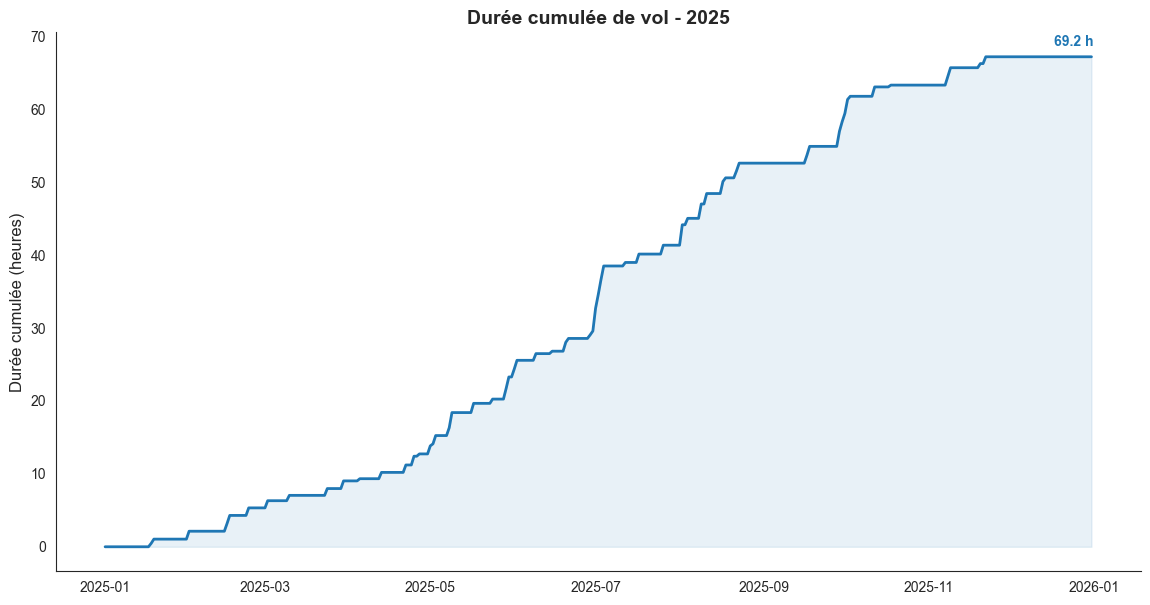

In [37]:
pilot="AdrienM"
year=2025

generate_pdf_report1(df=df, pilot=pilot, year=year)

In [ ]:
pilot="AdrienM"
year=2025
report_params, df_year, df_year_pilot, df_year_pilot_parapente, df_year_pilot_paramoteur = create_main_data(df=df, pilot=pilot, year=year)

if df_year_pilot.shape[0] > 0:
    report_params["title"] = f"""Statistiques des vols pour l'année {report_params["year_interest"]}"""
    chapters_dict = {
        "1": "Statistiques générales",
        "2": "Statistiques parapente",
        "3": "Statistiques paramoteur",
    }
    tables_dict = {
        "table_1_title" : f"Sites pratiqués :",
        "table_2_title" : f"Voiles utilisées :",
    }

    global_flight_params = get_flight_params(df=df_year_pilot)
    data_sites, data_voiles = create_data_for_tables(df_init=df_year_pilot)
    image_mois, image_jour, image_heure = create_images(df=df_year_pilot)
    
    parapente_flight_params = get_flight_params(df=df_year_pilot_parapente)
    data_sites_parapente, data_voiles_parapente = create_data_for_tables(df_init=df_year_pilot_parapente)
    image_mois_parapente, image_jour_parapente, image_heure_parapente = create_images(df=df_year_pilot_parapente)
    
    paramoteur_flight_params = get_flight_params(df=df_year_pilot_paramoteur)
    data_sites_paramoteur, data_voiles_paramoteur = create_data_for_tables(df_init=df_year_pilot_paramoteur)
    image_mois_paramoteur, image_jour_paramoteur, image_heure_paramoteur = create_images(df=df_year_pilot_paramoteur)

    pdf = initialize_pdf(report_params = report_params)
    links_dict, pdf = table_matieres(pdf = pdf, chapters_dict=chapters_dict)
    
    ##Chapter 1: Global
    pdf.print_chapter(chap_num=1, chap_title=chapters_dict["1"], link=links_dict["1"])
    pdf.general_stats(df = df_year_pilot, flight_params_dict = global_flight_params)
    pdf.create_table(data = data_sites, table_title=tables_dict["table_1_title"])
    pdf.ln(5)
    pdf.create_table(data = data_voiles, table_title=tables_dict["table_2_title"])
    pdf.image(name=image_mois, x=20, w=pdf.w-30, keep_aspect_ratio=True)
    pdf.image(name=image_jour, x=30, w=pdf.w-60, keep_aspect_ratio=True)
    pdf.image(name=image_heure, x=20, w=pdf.w-50, keep_aspect_ratio=True)

    ##Chapter 2: parapente
    pdf.print_chapter(chap_num=2, chap_title=chapters_dict["2"], link=links_dict["2"])
    if df_year_pilot_parapente.shape[0] > 0:
        pdf.general_stats(df = df_year_pilot_parapente, flight_params_dict = parapente_flight_params)
        pdf.create_table(data = data_sites_parapente, table_title=tables_dict["table_1_title"])
        pdf.ln(5)
        pdf.create_table(data = data_voiles_parapente, table_title=tables_dict["table_2_title"])
        pdf.image(name=image_mois_parapente, x=20, w=pdf.w-30, keep_aspect_ratio=True)
        pdf.image(name=image_jour_parapente, x=30, w=pdf.w-60, keep_aspect_ratio=True)
        pdf.image(name=image_heure_parapente, x=20, w=pdf.w-50, keep_aspect_ratio=True)

    ##Chapter 3: paramoteur
    pdf.print_chapter(chap_num=3, chap_title=chapters_dict["3"], link=links_dict["3"])
    if df_year_pilot_paramoteur.shape[0] > 0:
        pdf.general_stats(df = df_year_pilot_paramoteur, flight_params_dict = paramoteur_flight_params)
        pdf.create_table(data = data_sites_paramoteur, table_title=tables_dict["table_1_title"])
        pdf.ln(5)
        pdf.create_table(data = data_voiles_paramoteur, table_title=tables_dict["table_2_title"])
        pdf.image(name=image_mois_paramoteur, x=20, w=pdf.w-30, keep_aspect_ratio=True)
        pdf.image(name=image_jour_paramoteur, x=30, w=pdf.w-60, keep_aspect_ratio=True)
        pdf.image(name=image_heure_paramoteur, x=20, w=pdf.w-50, keep_aspect_ratio=True)

    pdf.output("test_pdf_01.pdf")

In [23]:
data_sites, data_voiles = create_data_for_tables(df_init=df_year_pilot)
data_sites_parapente, data_voiles_parapente = create_data_for_tables(df_init=df_year_pilot_parapente)

display(set(df_year_pilot_parapente["voile"]))

print(
    data_voiles,
)
print(
    data_voiles_parapente
)

{'boxer 2', 'daytona', 'dolpo', 'dolpo 3', 'leaf 3'}

,voile,nb_vols,total_duree_vol,moyenne_duree_vol,max_duree_vol,moyenne_vitesse_moyenne,max_vitesse_moyenne,moyenne_vitesse_max,max_vitesse_max,moyenne_gain,max_gain,moyenne_vario_max,max_vario_max,moyenne_g_max,max_g_max,nb_pilotes,nb_tot_minutes
0,daytona,69,57 h et 6 min,49.7,98.7,32.8,40.8,61.5,85,634.8,1626,2.7,4.9,1.5,3.2,1,3426.333333
1,dolpo 3,50,8 h et 27 min,10.1,61.4,16.4,30.6,45.9,54,194.0,788,4.1,7.1,1.4,1.8,1,506.550000
2,leaf 3,33,6 h et 20 min,11.5,48.1,16.6,25.8,43.8,53,240.1,760,3.3,6.3,1.5,2.5,1,380.366667
3,boxer 2,2,0 h et 7 min,3.5,3.8,17.4,19.0,45.5,49,175.0,198,4.6,4.9,1.3,1.3,1,6.983333
4,dolpo,2,0 h et 7 min,3.4,3.7,17.8,19.3,43.0,44,162.5,164,4.7,5.2,1.3,1.4,1,6.783333


{'boxer 2', 'dolpo', 'dolpo 3', 'leaf 3'}

,voile,nb_vols,total_duree_vol,moyenne_duree_vol,max_duree_vol,moyenne_vitesse_moyenne,max_vitesse_moyenne,moyenne_vitesse_max,max_vitesse_max,moyenne_gain,max_gain,moyenne_vario_max,max_vario_max,moyenne_g_max,max_g_max,nb_pilotes,nb_tot_minutes
0,daytona,69,57 h et 6 min,49.7,98.7,32.8,40.8,61.5,85,634.8,1626,2.7,4.9,1.5,3.2,1,3426.333333
1,dolpo 3,50,8 h et 27 min,10.1,61.4,16.4,30.6,45.9,54,194.0,788,4.1,7.1,1.4,1.8,1,506.550000
2,leaf 3,33,6 h et 20 min,11.5,48.1,16.6,25.8,43.8,53,240.1,760,3.3,6.3,1.5,2.5,1,380.366667
3,boxer 2,2,0 h et 7 min,3.5,3.8,17.4,19.0,45.5,49,175.0,198,4.6,4.9,1.3,1.3,1,6.983333
4,dolpo,2,0 h et 7 min,3.4,3.7,17.8,19.3,43.0,44,162.5,164,4.7,5.2,1.3,1.4,1,6.783333


{'boxer 2', 'dolpo', 'dolpo 3', 'leaf 3'}

[['Voile', 'Nombre de vols', 'Durée totale de vol', 'Durée moy. de vol', 'Vitesse moyenne', 'gain max', 'vario max', 'g max'], ['daytona', '69', '57 h et 6 min', '49.7', '32.8', '1626', '4.9', '3.2'], ['dolpo 3', '50', '8 h et 27 min', '10.1', '16.4', '788', '7.1', '1.8'], ['leaf 3', '33', '6 h et 20 min', '11.5', '16.6', '760', '6.3', '2.5'], ['boxer 2', '2', '0 h et 7 min', '3.5', '17.4', '198', '4.9', '1.3'], ['dolpo', '2', '0 h et 7 min', '3.4', '17.8', '164', '5.2', '1.4']]
[['Voile', 'Nombre de vols', 'Durée totale de vol', 'Durée moy. de vol', 'Vitesse moyenne', 'gain max', 'vario max', 'g max'], ['daytona', '69', '57 h et 6 min', '49.7', '32.8', '1626', '4.9', '3.2'], ['dolpo 3', '50', '8 h et 27 min', '10.1', '16.4', '788', '7.1', '1.8'], ['leaf 3', '33', '6 h et 20 min', '11.5', '16.6', '760', '6.3', '2.5'], ['boxer 2', '2', '0 h et 7 min', '3.5', '17.4', '198', '4.9', '1.3'], ['dolpo', '2', '0 h et 7 min', '3.4', '17.8', '164', '5.2', '1.4']]


In [41]:
plot_mois_dict = {
    "cat_feature":"mois",
    "num_feature":"nb_vols",
    "text":"total_duree_vol",
    "y_title":"Nombre de vols", 
    "x_title":None,
}

plot_jour_dict = {
    "cat_feature":"jour_semaine",
    "num_feature":"nb_vols",
    "text":"total_duree_vol",
    "y_title":"Nombre de vols",
    "x_title":"Jour de la semaine",
}

plot_heure_dict = {
    "cat_feature":"heure_decolage",
    "num_feature":"nb_vols",
    "text":"total_duree_vol",
    "y_title":"Nombre de vols",
    "x_title":"Heure de décolage",
}
fig_mois = create_plots(df_stat_mois_vol, plot_param=plot_mois_dict)
fig_jour = create_plots(df_stat_jour_vol, plot_param=plot_jour_dict)
fig_heure = create_plots(df_stat_heure_vol, plot_param=plot_heure_dict)

image_fig_mois = fig_mois.to_image(format="png", engine="kaleido", scale=5)
image_fig_jour = fig_jour.to_image(format="png", engine="kaleido", scale=5)
image_fig_heure = fig_heure.to_image(format="png", engine="kaleido", scale=5)

image_mois = io.BytesIO(image_fig_mois)
image_jour = io.BytesIO(image_fig_jour)
image_heure = io.BytesIO(image_fig_heure)

# fig_mois.show()
# fig_jour.show()
# fig_heure.show()

In [ ]:
global_flight_params

In [47]:
df_sites = (
    df_stat_sites[["site","nb_vols","total_duree_vol","moyenne_duree_vol","moyenne_vitesse_moyenne"]]
).applymap(str)

df_voiles = (
    df_stat_voile[["voile","nb_vols","total_duree_vol","moyenne_duree_vol","moyenne_vitesse_moyenne", "max_gain", "max_vario_max", "max_g_max"]]
).applymap(str)

# data_cols_sites = [list(df_sites)]  # Get list of dataframe columns
data_cols_sites = [[
    "Site", "Nombre de vols", "Durée totale de vol",
    "Durée moy. de vol", "Vitesse moyenne",
]]
data_rows_sites = df_sites.values.tolist()  # Get list of dataframe rows
data_sites = data_cols_sites + data_rows_sites  # Combine columns and rows in one list


data_cols_voiles = [[
    "Voile", "Nombre de vols", "Durée totale de vol",
    "Durée moy. de vol", "Vitesse moyenne", "gain max", "vario max", "g max" 
]]
data_rows_voiles = df_voiles.values.tolist()  # Get list of dataframe rows
data_voiles = data_cols_voiles + data_rows_voiles  # Combine columns and rows in one list


report_params["title"] = f"""Statistiques des vols pour l'année {report_params["year_interest"]}"""
chapters_dict = {
    "1": "Statistiques générales",
    "2": "Statistiques paramoteur",
    "3": "Statistiques parapente",
}
tables_dict = {
    "table_1_title" : f"Sites pratiqués :",
    "table_2_title" : f"Voiles utilisées :",
}


pdf = initialize_pdf(report_params = report_params)
links_dict, pdf = table_matieres(pdf = pdf, chapters_dict=chapters_dict)
pdf.print_chapter(chap_num=1, chap_title=chapters_dict["1"], link=links_dict["1"])
pdf.general_stats(df = df_year_pilot, flight_params_dict = global_flight_params)
pdf.create_table(data = data_sites, table_title=tables_dict["table_1_title"])
pdf.ln(5)
pdf.create_table(data = data_voiles, table_title=tables_dict["table_2_title"])
pdf.image(name=image_mois, x=20, w=pdf.w-30, keep_aspect_ratio=True)
pdf.image(image_jour, x=30, w=pdf.w-60, keep_aspect_ratio=True)
pdf.image(image_heure, x=20, w=pdf.w-50, keep_aspect_ratio=True)




pdf.print_chapter(chap_num=2, chap_title=chapters_dict["2"], link=links_dict["2"])
pdf.set_font('helvetica', size=11)
pdf.cell(
    w = 80,
    h = 8,
    text = f"TEST d'impression pdf : **{global_flight_params['nb_tot_vols']}**",
    markdown=True
)


pdf.output("test_pdf_01.pdf")
